[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/notebooks/04-kiwi-semantic-vs-instance.ipynb)

# Semantic, Instance & Panoptic 3D Segmentation — Definitions, Neural Paradigms & Foundation-Model Workflows

*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027)*  
*Updated by Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab*

> **Kiwi Challenge Notebook Sequence (`Lab4-Comp-Imag/Kiwi-challenge`):**
> 1. `01-kiwi-explore.ipynb` — 3D NIfTI/DICOM headers, voxel geometry & coordinate systems
> 2. `02-kiwi-seeds-explore.ipynb` — 2D single-slice filtering, thresholding, unsupervised K-means & the Dagstuhl/CUHK 3D variational milestone
> 3. `03-kiwi-paradigms-and-verification.ipynb` — Full 3D segmentation ladder, quantitative "lesion load", Curated 3D Micro-GT scoring & the **4-Panel Semi-Verifiability Dashboard**
> 4. `03b-kiwi-interactive-gt-and-interrater.ipynb` — Interactive 3D Jupyter-Widget delineation, personalized Ground Truth (`MyStuff/`), **Inter-Rater Variability**, **Panoptic Quality ($\text{PQ}$)** & **STAPLE Consensus**
> 5. **`04-kiwi-semantic-vs-instance.ipynb` (this deep dive)** — Formal definitions of **Semantic, Instance & Panoptic** segmentation, the **Label-Permutation Symmetry** problem, head-to-head **3D PyTorch Semantic U-Net vs. Deep Distance/Cellpose-Flow Instance U-Net**, and **Promptable Foundation-Model (SAM / MedSAM / SAM-2)** 3D workflows

---

## Part 1 — Definitions, Concepts & Mathematical Foundations

When a clinician or biologist says *"segment the lesions / cells / seeds in this 3D scan"*, they may actually mean **three mathematically distinct computational tasks**. Confusing them is one of the most frequent methodological mistakes in biomedical AI.

### 1.1 The Taxonomy of Biomedical Image Segmentation

Let $\Omega \subset \mathbb{Z}^3$ denote the 3D discrete voxel lattice of our MRI scan (`256 × 256 × 128` voxels) with intensity volume $X: \Omega \to \mathbb{R}$.

| Task | Mathematical Output Map | Core Question Answered | "Stuff" vs. "Things" | Kiwi Challenge & Clinical Biomarker |
| :--- | :--- | :--- | :--- | :--- |
| **1. Semantic Segmentation** | $S: \Omega \to \{0, 1, \dots, C-1\}$ | *"Which **tissue class** is at voxel $\mathbf{x}$?"* | **Stuff** (amorphous regions: air, pericarp gel, fibrous core, total seed tissue) | **Total seed volume $V_{\text{seeds}}$ ($\text{mm}^3$)** & **parenchymal lesion load ($\%$)**; MS total white-matter lesion volume; organ volumetry |
| **2. Instance Segmentation** | $I: \Omega \to \{0, 1, 2, \dots, N\}$ | *"Which **individual countable object** $k$ does voxel $\mathbf{x}$ belong to?"* | **Things** (countable discrete objects: individual seeds, cell nuclei, microbleeds) | **Total seed count $N$**, **single-seed volume distribution**, & **3D spatial point-process geometry**; metastatic nodule count; 3D cell count |
| **3. Panoptic Segmentation** *(Kirillov et al., 2019)* | $P: \Omega \to \mathcal{C} \times (\mathbb{N} \cup \{\varnothing\})$ | *"What is the tissue class of **every** voxel, AND which instance ID if it is a countable object?"* | **Unifies Stuff + Things** across the entire 3D scene | Simultaneous anatomy parcellation (`Columella`, `Locular Gel`, `Outer Cortex`) **plus** individual seed instances `(class=Seed, id=1..N)` |

---

### 1.2 The Fundamental Obstacle: *Why Can't a Neural Network Directly Predict Instance IDs `1..N`?*

In **Semantic Segmentation**, class integers have **fixed universal meaning** across every patient and every slice:
- `0` = Air / Background, `1` = Bright Pericarp Gel, `2` = Dark Fibrous Core (*Columella*) / Peel, `3` = Seed Tissue.
- Therefore, a 3D U-Net with `4` output channels can be trained directly with standard voxelwise **Cross-Entropy + Soft Dice Loss**.

Now ask: *Why can't we simply give a 3D U-Net `1,500` output channels and train it with Cross-Entropy on `kiwi_micro_gt_labels.nii.gz` (`ID = 1..98`)?* Two fundamental mathematical reasons make direct ID classification **ill-posed**:

1. **Label-Permutation Symmetry (Invariance):**  
   Instance IDs are **arbitrary names**. If Rater 1 calls two seeds `(ID=7, ID=42)` and Rater 2 calls the exact same two seeds `(ID=42, ID=7)`, the two instance segmentations are **100% identical**! Formally, for any bijection (permutation) $\pi: \{1,\dots,N\} \to \{1,\dots,N\}$ with $\pi(0)=0$, the relabeled volume $\pi \circ I$ represents the exact same partition of $\Omega$. Standard voxelwise cross-entropy is *not* permutation-invariant — it would penalize a swapped ID as a 100% error and force the network to memorize arbitrary spatial coordinates rather than seed appearance.
2. **Unbounded & Variable Cardinality ($N$ changes per scan):**  
   A small axial patch may contain `0` seeds (in the central columella) or `12` seeds, whereas the whole kiwifruit contains `~1,400` seeds, and a microscopy volume may contain `50,000` nuclei. A fixed $K$-class softmax head cannot represent an arbitrary number of instances.

---

### 1.3 How Modern Biomedical AI Solves 3D Instance Segmentation: Four Paradigms

To respect **permutation invariance** while handling **packed, touching 3D objects**, modern biomedical segmentation methods fall into **four architectural paradigms**:

1. **Paradigm A — Semantic-First + 3D Connected Components (`3D U-Net` / `nnU-Net` + `cc3d`):**  
   Train a network to predict semantic seed probability $P(\text{seed} \mid \mathbf{x}) \in [0, 1]$, threshold at `0.5`, and assign distinct IDs to disconnected 3D islands via 26-connectivity (`scipy.ndimage.label`).
   - *When it works:* Sparse, well-separated lesions.
   - *When it fails:* Whenever two seeds touch within 1 voxel (or share partial-volume blur across `dz = 0.50 mm`), connected components **fuses them into one giant instance**, achieving high **Semantic Dice (`> 0.85`)** while failing at counting!
2. **Paradigm B — 3-Class Core–Boundary–Background (`DCAN` / `Border U-Net`):**  
   Predict `3` semantic classes: `0 = Background`, `1 = Eroded Seed Interior`, `2 = Touching Inter-Seed Border Rim`. Subtracting class `2` carves a 1-voxel "moat" between touching seeds before running connected components.
3. **Paradigm C — Geometric & Vector-Field Surrogate Regression (`Deep Watershed`, `StarDist-3D`, `HoVer-Net`, `Cellpose-3D`):**  
   Instead of predicting integer IDs, train a multi-head 3D network to predict **continuous, permutation-invariant geometric fields** inside every instance:
   - **Normalized 3D Center-Distance Field $\hat{D}(\mathbf{x}) \in [0, 1]$ (`Deep Watershed` / `StarDist`):** Every seed's physical center has $\hat{D} = 1.0$, decaying smoothly to $0.0$ at its boundary. Even when two seeds touch, $\hat{D}$ preserves **two distinct local maxima** separated by a valley, enabling marker-controlled 3D watershed!
   - **3D Unit Center-Vector Flows $\vec{v}(\mathbf{x}) \in \mathbb{R}^3$ (`Cellpose`, [Stringer et al., *Nature Methods* 2021](https://www.nature.com/articles/s41592-020-01018-x); `HoVer-Net`, [Graham et al., *MedIA* 2019](https://pubmed.ncbi.nlm.nih.gov/31669916/)):** Every foreground voxel predicts a unit vector pointing toward *its own instance's center of mass*:
     $$\vec{v}(\mathbf{x}) = \frac{\boldsymbol{\mu}_{I(\mathbf{x})} - \mathbf{x}}{\|\boldsymbol{\mu}_{I(\mathbf{x})} - \mathbf{x}\|_2 + \varepsilon}$$
     At inference, every foreground voxel moves iteratively along the predicted flow field via **Euler dynamical integration**:
     $$\mathbf{x}^{(t+1)} = \mathbf{x}^{(t)} + \eta \, \vec{v}\!\left(\mathbf{x}^{(t)}\right), \qquad t = 0, 1, \dots, T-1$$
     Voxels belonging to two touching seeds flow in **opposite directions** at their shared interface and condense into **two compact, well-separated point clouds** (sinks/attractors)!
4. **Paradigm D — Promptable Vision Foundation Models (`SAM`, `SAM-2`, `MedSAM`, `MicroSAM`):**  
   Decouple *finding objects* (via point prompts, bounding boxes, or a lightweight peak detector) from *delineating masks* (via a prompt-conditioned Mask Decoder). For 3D medical volumes, **[SAM-2](https://arxiv.org/abs/2408.00714)** and **[MedSAM-2](https://arxiv.org/abs/2408.03322)** treat consecutive axial slices $z = 1 \dots 128$ like frames of a video, propagating 2D instance prompts across slices via cross-slice memory / IoU tracking!

---

### 1.4 Evaluation Metrics Reference (`Metrics Reloaded` & Panoptic Quality)

Following **[Metrics Reloaded](https://www.nature.com/articles/s41592-023-02151-z)** *(Maier-Hein et al., Nature Methods 2024)* and **[Kirillov et al. (CVPR 2019)](https://arxiv.org/abs/1801.00868)**:
- **Semantic Overlap (`Voxel Dice / DSC`):** $\text{DSC}(S_{\text{pred}}, S_{\text{gt}}) = \frac{2 |S_{\text{pred}} \cap S_{\text{gt}}|}{|S_{\text{pred}}| + |S_{\text{gt}}|}$ — measures total foreground tissue overlap; **blind to instance merges**.
- **Instance Matching & Kirillov's Uniqueness Theorem:** Between predicted instances $\{p_i\}$ and ground-truth instances $\{g_j\}$, compute 3D $\text{IoU}(p_i, g_j) = \frac{|p_i \cap g_j|}{|p_i \cup g_j|}$.
  - *Theorem (Kirillov 2019):* Because instances within a mask are mutually disjoint, for **strict threshold $\tau = 0.5$**, at most one predicted instance can have $\text{IoU}(p_i, g_j) > 0.5$ with a given $g_j$ (and vice versa) — making the matching **provably unique**!
  - *Small-Object Caveat (`Metrics Reloaded`):* For tiny 3D objects (`~35–60` anisotropic voxels, like cerebral microbleeds or kiwi seeds), a 1-voxel boundary shift drops 3D IoU from `1.0` to `~0.38–0.48`. Below, we use **optimal 1-to-1 Hungarian assignment** (`scipy.optimize.linear_sum_assignment`) and inspect $\tau = 0.25$ (as well as $\tau = 0.50$).
- **Panoptic Quality ($\text{PQ} = \text{SQ} \times \text{RQ}$):**
  $$\text{PQ} = \underbrace{\frac{\sum_{(p,g) \in \text{TP}} \text{IoU}(p, g)}{|\text{TP}|}}_{\text{Segmentation Quality (SQ)}} \times \underbrace{\frac{|\text{TP}|}{|\text{TP}| + \frac{1}{2}|\text{FP}| + \frac{1}{2}|\text{FN}|}}_{\text{Recognition Quality (RQ = Instance } F_1\text{)}}$$
- **Topological Instance Error Counts:**
  - **Merge Clumps:** Predicted instances that absorb $\ge 2$ distinct ground-truth seeds (at $\ge 25\%$ recall each).
  - **Split Errors:** Ground-truth seeds fractured across $\ge 2$ distinct predicted fragments.

## Step 0 — Environment Setup & Runtime Device Selection (`CUDA` → `MPS` → `CPU`)

Runs out of the box locally (`uv run jupyter lab` with `bmed365-2027`) and in **Google Colab** (automatically picking GPU `cuda` on Colab T4, `mps` on Apple Silicon Macs, or `cpu` anywhere else).

In [1]:
import json
import sys
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage import filters, measure, morphology, segmentation
from sklearn.cluster import KMeans

def _ensure_pkg(import_name: str, pip_name: str | None = None):
    import importlib.util
    if importlib.util.find_spec(import_name) is None:
        import subprocess
        pkg = pip_name or import_name
        print(f"Installing {pkg} for this session...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

_ensure_pkg("nibabel")
_ensure_pkg("torch")

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams["figure.dpi"] = 115

import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F

def get_best_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = get_best_device()
torch.manual_seed(2027)
np.random.seed(2027)

GITHUB_RAW_BASE = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"

def resolve_kiwi_file(rel_path: str) -> Path:
    for cand in [Path("..") / rel_path, Path("Lab4-Comp-Imag/Kiwi-challenge") / rel_path, Path(rel_path)]:
        if cand.exists():
            return cand
    dst = Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {rel_path} from GitHub for Colab session...")
    urllib.request.urlretrieve(f"{GITHUB_RAW_BASE}/{rel_path}", dst)
    return dst

nii_path = resolve_kiwi_file("data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz")
gt_nii_path = resolve_kiwi_file("data/kiwi_micro_gt_labels.nii.gz")
gt_json_path = resolve_kiwi_file("data/kiwi_micro_gt_roi.json")

nii_img = nib.load(str(nii_path))
vol = nii_img.get_fdata(dtype=np.float32)
spacing = tuple(float(s) for s in nii_img.header.get_zooms()[:3])  # (0.234375, 0.234375, 0.5) mm
vox_vol_mm3 = float(np.prod(spacing))

gt_full = np.asarray(nib.load(str(gt_nii_path)).dataobj, dtype=np.uint16)
gt_meta = json.loads(gt_json_path.read_text(encoding="utf-8"))
RX0, RX1 = gt_meta["roi_bounds_voxel_xyz"]["x"]  # [128, 208)
RY0, RY1 = gt_meta["roi_bounds_voxel_xyz"]["y"]  # [128, 208)
RZ0, RZ1 = gt_meta["roi_bounds_voxel_xyz"]["z"]  # [56, 72)

print(f"PyTorch {torch.__version__} | Compute device: {DEVICE}")
print(f"7T Kiwi MRI volume : shape={vol.shape}, spacing={spacing} mm ({vox_vol_mm3:.5f} mm³/voxel)")
print(f"Micro-GT ROI bounds: x=[{RX0},{RX1}), y=[{RY0},{RY1}), z=[{RZ0},{RZ1}) -> {gt_meta['n_seeds_in_roi']} labeled 3D seeds")

PyTorch 2.15.0 | Compute device: mps
7T Kiwi MRI volume : shape=(256, 256, 128), spacing=(0.234375, 0.234375, 0.5) mm (0.02747 mm³/voxel)
Micro-GT ROI bounds: x=[128,208), y=[128,208), z=[56,72) -> 98 labeled 3D seeds


---

## Step 1 — Visualizing the Target Representations: Semantic, Panoptic, Border, Distance & Cellpose Flows

Before training any model, let us construct and visualize **all five target representations** on the exact same 7T MRI sector (`z = 64`) — and verify mathematically that **Euler dynamical sink-tracking** on a 3D unit center-flow field $\vec{v}(\mathbf{x})$ cleanly separates touching 3D seeds without needing arbitrary integer IDs during training!

Ground-Truth ROI uint16 seeds     : 98 instances
Naive 3D CC on binary GT          : 66 components (touching seeds merged!)
Cellpose-style 3D Euler Flow Recon: 100 instances recovered from continuous flows!


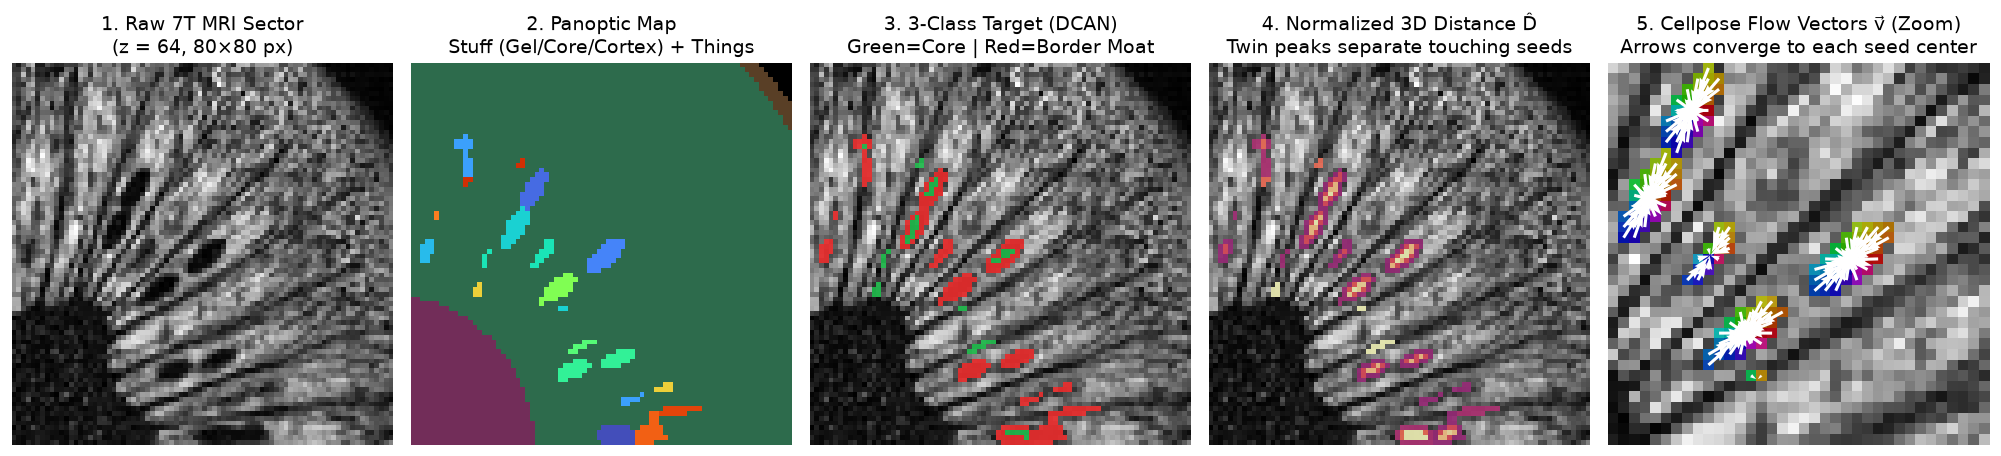

In [2]:
def build_panoptic_stuff_map_full(vol_3d: np.ndarray, sp=spacing) -> tuple[np.ndarray, np.ndarray]:
    """Segment whole-fruit anatomical 'Stuff' classes:
    0 = Background Air, 1 = Outer Cortex/Peel, 2 = Bright Locular Gel, 3 = Dark Central Columella.
    Also returns whole-fruit foreground mask."""
    v_sm = ndi.gaussian_filter(vol_3d, sigma=(1.2 / sp[0], 1.2 / sp[1], 1.2 / sp[2]))
    fg_r = v_sm > (filters.threshold_otsu(v_sm[::2, ::2, ::2]) * 0.35)
    fg_f = np.zeros_like(fg_r)
    for z in range(vol_3d.shape[2]):
        fg_f[:, :, z] = ndi.binary_fill_holes(fg_r[:, :, z])
    fg_f = ndi.binary_fill_holes(fg_f)
    lbl_fg, _ = ndi.label(fg_f)
    fruit_mask = lbl_fg == (1 + int(np.argmax(np.bincount(lbl_fg.ravel())[1:])))
    fruit_interior = ndi.binary_erosion(fruit_mask, iterations=4)

    # Radial distance from slice-wise fruit centroid to identify central fibrous columella
    stuff = np.zeros(vol_3d.shape, dtype=np.uint8)
    stuff[fruit_mask] = 1  # Outer cortex / peel ring
    stuff[fruit_interior] = 2  # Pericarp / locular gel

    yy, xx = np.meshgrid(np.arange(vol_3d.shape[1]), np.arange(vol_3d.shape[0]))
    for z in range(vol_3d.shape[2]):
        m = fruit_mask[:, :, z]
        if m.sum() < 100:
            continue
        cx, cy = float(xx[m].mean()), float(yy[m].mean())
        r_px = np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2)
        r_fruit = np.sqrt(m.sum() / np.pi)
        # Central columella is dark in T2 RARE and near center (r < 0.28 * R_fruit)
        col_mask = m & (r_px < 0.28 * r_fruit) & (v_sm[:, :, z] < np.percentile(v_sm[:, :, z][m], 55))
        stuff[:, :, z][col_mask] = 3
    return stuff, fruit_mask


def build_instance_surrogate_targets(inst_lbl: np.ndarray, sp=spacing) -> dict[str, np.ndarray]:
    """From a uint16 3D instance volume, construct permutation-invariant training targets:
    - sem_fg     : float32 {0, 1} binary seed mask
    - border_3c  : int64 {0=Bg, 1=Seed Core, 2=Seed Boundary / Inter-Seed Rim}
    - norm_dist  : float32 [0, 1] per-instance normalized 3D physical distance to boundary
    - flow_xyz   : float32 (3, X, Y, Z) unit physical vector pointing toward each instance's 3D centroid
    """
    sem_fg = (inst_lbl > 0).astype(np.float32)
    norm_dist = np.zeros(inst_lbl.shape, dtype=np.float32)
    flow_xyz = np.zeros((3,) + inst_lbl.shape, dtype=np.float32)
    border_3c = np.zeros(inst_lbl.shape, dtype=np.int64)

    for prop in measure.regionprops(inst_lbl):
        s0, s1, s2 = prop.slice
        # Pad local bounding box by 1 voxel so distance_transform_edt sees true 0 background on all sides
        sub = np.pad(inst_lbl[s0, s1, s2] == prop.label, pad_width=1, mode="constant", constant_values=False)
        d_local = ndi.distance_transform_edt(sub, sampling=sp)[1:-1, 1:-1, 1:-1]
        m_local = sub[1:-1, 1:-1, 1:-1]
        d_max = float(d_local.max()) if d_local.max() > 0 else 1.0
        norm_dist[s0, s1, s2][m_local] = (d_local[m_local] / d_max).astype(np.float32)

        # Core vs. 1-voxel boundary moat for Paradigm B (3-Class U-Net)
        eroded = ndi.binary_erosion(sub, iterations=1)[1:-1, 1:-1, 1:-1]
        if eroded.sum() == 0:
            eroded = m_local
        border_3c[s0, s1, s2][m_local] = 2
        border_3c[s0, s1, s2][eroded] = 1

        # Cellpose-style 3D unit vector pointing to instance centroid (in voxel units scaled by spacing)
        coords = prop.coords  # (N_vox, 3)
        center = coords.mean(axis=0)  # (cx, cy, cz)
        vec = center[None, :] - coords.astype(np.float32)
        # Scale by physical spacing so vector direction is physically isotropic, then convert to voxel step direction
        norm = np.linalg.norm(vec * np.asarray(sp, dtype=np.float32)[None, :], axis=1, keepdims=True) + 1e-6
        unit_phys = (vec * np.asarray(sp, dtype=np.float32)[None, :]) / norm
        # Convert physical unit vector back into normalized voxel-grid displacement
        step_vox = unit_phys / np.array([1.0, 1.0, sp[2] / sp[0]], dtype=np.float32)[None, :]
        flow_xyz[0, coords[:, 0], coords[:, 1], coords[:, 2]] = step_vox[:, 0]
        flow_xyz[1, coords[:, 0], coords[:, 1], coords[:, 2]] = step_vox[:, 1]
        flow_xyz[2, coords[:, 0], coords[:, 1], coords[:, 2]] = step_vox[:, 2]

    return {"sem_fg": sem_fg, "border_3c": border_3c, "norm_dist": norm_dist, "flow_xyz": flow_xyz}


def euler_flow_decode_3d(fg_mask: np.ndarray, flow_xyz: np.ndarray, n_steps: int = 24, step_size: float = 0.75, cluster_radius_mm: float = 0.68, sp=spacing) -> np.ndarray:
    """Cellpose-inspired 3D Euler dynamical sink tracking:
    Move every foreground voxel along flow_xyz for n_steps, then group converged sink positions!"""
    pts = np.argwhere(fg_mask)
    if len(pts) == 0:
        return np.zeros(fg_mask.shape, dtype=np.uint16)

    pos = pts.astype(np.float32).copy()
    sx, sy, sz = fg_mask.shape
    for _ in range(n_steps):
        ix = np.clip(np.round(pos[:, 0]).astype(int), 0, sx - 1)
        iy = np.clip(np.round(pos[:, 1]).astype(int), 0, sy - 1)
        iz = np.clip(np.round(pos[:, 2]).astype(int), 0, sz - 1)
        vx = flow_xyz[0, ix, iy, iz]
        vy = flow_xyz[1, ix, iy, iz]
        vz = flow_xyz[2, ix, iy, iz]
        pos[:, 0] = np.clip(pos[:, 0] + step_size * vx, 0, sx - 1)
        pos[:, 1] = np.clip(pos[:, 1] + step_size * vy, 0, sy - 1)
        pos[:, 2] = np.clip(pos[:, 2] + step_size * vz, 0, sz - 1)

    # Accumulate converged sink density on a sub-voxel grid (2x in-plane) and find sink attractors
    sink_hist = np.zeros(fg_mask.shape, dtype=np.float32)
    rx = np.clip(np.round(pos[:, 0]).astype(int), 0, sx - 1)
    ry = np.clip(np.round(pos[:, 1]).astype(int), 0, sy - 1)
    rz = np.clip(np.round(pos[:, 2]).astype(int), 0, sz - 1)
    np.add.at(sink_hist, (rx, ry, rz), 1.0)
    sink_sm = ndi.gaussian_filter(sink_hist, sigma=(0.45, 0.45, 0.35))

    # Dilate attractors within physical radius cluster_radius_mm to merge discretisation jitter at sink
    rad_vox = (
        max(1, int(round(cluster_radius_mm / sp[0]))),
        max(1, int(round(cluster_radius_mm / sp[1]))),
        max(1, int(round(cluster_radius_mm / sp[2]))),
    )
    xx, yy, zz = np.ogrid[-rad_vox[0]:rad_vox[0]+1, -rad_vox[1]:rad_vox[1]+1, -rad_vox[2]:rad_vox[2]+1]
    fp = ((xx * sp[0]) ** 2 + (yy * sp[1]) ** 2 + (zz * sp[2]) ** 2) <= (cluster_radius_mm ** 2)
    peaks = (sink_sm == ndi.maximum_filter(sink_sm, footprint=fp)) & (sink_hist >= 2.0)
    peak_lbl, n_sinks = ndi.label(peaks)
    if n_sinks == 0:
        lbl_fallback, _ = ndi.label(fg_mask)
        return lbl_fallback.astype(np.uint16)

    # Assign each converged particle to its nearest physical sink attractor
    sink_coords = np.array(ndi.center_of_mass(sink_hist, peak_lbl, range(1, n_sinks + 1)), dtype=np.float32)
    pos_mm = pos * np.asarray(sp, dtype=np.float32)[None, :]
    sinks_mm = sink_coords * np.asarray(sp, dtype=np.float32)[None, :]
    # Chunked nearest-sink assignment for memory safety
    assigned_ids = np.zeros(len(pts), dtype=np.uint16)
    for start in range(0, len(pts), 4096):
        d2 = np.sum((pos_mm[start:start+4096, None, :] - sinks_mm[None, :, :]) ** 2, axis=2)
        assigned_ids[start:start+4096] = (np.argmin(d2, axis=1) + 1).astype(np.uint16)

    out = np.zeros(fg_mask.shape, dtype=np.uint16)
    out[pts[:, 0], pts[:, 1], pts[:, 2]] = assigned_ids
    return out


stuff_full, fruit_mask_full = build_panoptic_stuff_map_full(vol)
roi_img = vol[RX0:RX1, RY0:RY1, RZ0:RZ1]
roi_gt = gt_full[RX0:RX1, RY0:RY1, RZ0:RZ1]
roi_stuff = stuff_full[RX0:RX1, RY0:RY1, RZ0:RZ1]
targets_roi = build_instance_surrogate_targets(roi_gt)

# Verify exact oracle recovery: Naive CC on binary vs. Euler Sink-Flow Decoding on ground-truth flows
cc_oracle, n_cc_oracle = ndi.label(roi_gt > 0)
flow_oracle = euler_flow_decode_3d(roi_gt > 0, targets_roi["flow_xyz"])
print(f"Ground-Truth ROI uint16 seeds     : {len(np.unique(roi_gt)) - 1} instances")
print(f"Naive 3D CC on binary GT          : {n_cc_oracle} components (touching seeds merged!)")
print(f"Cellpose-style 3D Euler Flow Recon: {len(np.unique(flow_oracle)) - 1} instances recovered from continuous flows!")

# 5-Panel Concept Visualization on Slice z = 64 (ROI z_loc = 8)
z_loc = 8
fig, axes = plt.subplots(1, 5, figsize=(17.5, 3.8))
sl_raw = roi_img[:, :, z_loc].T

axes[0].imshow(sl_raw, cmap="gray", origin="lower")
axes[0].set_title("1. Raw 7T MRI Sector\n(z = 64, 80×80 px)")

# Panel 2: Panoptic Map (Stuff background + Thing seed instances)
pan_rgb = np.zeros(sl_raw.shape + (3,), dtype=np.float32)
st_sl = roi_stuff[:, :, z_loc].T
pan_rgb[st_sl == 1] = [0.35, 0.25, 0.15]  # Outer cortex (Stuff)
pan_rgb[st_sl == 2] = [0.18, 0.42, 0.30]  # Bright locular gel (Stuff)
pan_rgb[st_sl == 3] = [0.45, 0.18, 0.35]  # Central columella (Stuff)
gt_sl = roi_gt[:, :, z_loc].T
cmap_turbo = plt.get_cmap("turbo")
for uid in np.unique(gt_sl):
    if uid == 0:
        continue
    pan_rgb[gt_sl == uid] = cmap_turbo((((int(uid) * 7) % 23) + 1) / 24.0)[:3]
axes[1].imshow(pan_rgb, origin="lower")
axes[1].set_title("2. Panoptic Map\nStuff (Gel/Core/Cortex) + Things")

# Panel 3: 3-Class Core vs. Border Rim (Paradigm B)
axes[2].imshow(sl_raw, cmap="gray", origin="lower")
b3_sl = targets_roi["border_3c"][:, :, z_loc].T
b3_rgb = np.zeros(sl_raw.shape + (4,), dtype=np.float32)
b3_rgb[b3_sl == 1] = [0.15, 0.85, 0.35, 0.80]  # Core = Green
b3_rgb[b3_sl == 2] = [1.00, 0.20, 0.20, 0.85]  # Moat/Border = Red
axes[2].imshow(b3_rgb, origin="lower")
axes[2].set_title("3. 3-Class Target (DCAN)\nGreen=Core | Red=Border Moat")

# Panel 4: Continuous Normalized 3D Distance Transform (Paradigm C1: Deep Watershed / StarDist)
axes[3].imshow(sl_raw, cmap="gray", origin="lower")
d_sl = targets_roi["norm_dist"][:, :, z_loc].T
axes[3].imshow(np.ma.masked_where(d_sl <= 0, d_sl), cmap="magma", alpha=0.88, origin="lower", vmin=0, vmax=1)
axes[3].set_title("4. Normalized 3D Distance D̂\nTwin peaks separate touching seeds")

# Panel 5: Cellpose-Style Center-Vector Flow Field (Zoomed 36×36 crop to show quiver arrows clearly!)
zx0, zx1, zy0, zy1 = 18, 54, 22, 58
axes[4].imshow(roi_img[zx0:zx1, zy0:zy1, z_loc].T, cmap="gray", origin="lower")
fx_sub = targets_roi["flow_xyz"][0, zx0:zx1, zy0:zy1, z_loc].T
fy_sub = targets_roi["flow_xyz"][1, zx0:zx1, zy0:zy1, z_loc].T
fg_sub = roi_gt[zx0:zx1, zy0:zy1, z_loc].T > 0
ang = (np.arctan2(fy_sub, fx_sub) + np.pi) / (2 * np.pi)
axes[4].imshow(np.ma.masked_where(~fg_sub, ang), cmap="hsv", alpha=0.65, origin="lower", vmin=0, vmax=1)
yy_q, xx_q = np.mgrid[0 : zy1 - zy0, 0 : zx1 - zx0]
m_q = fg_sub
axes[4].quiver(xx_q[m_q], yy_q[m_q], fx_sub[m_q], fy_sub[m_q], color="white", scale=14, width=0.008)
axes[4].set_title("5. Cellpose Flow Vectors v⃗ (Zoom)\nArrows converge to each seed center")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

---

## Step 2 — Spatial Train / Held-Out Test Split (Zero Data Leakage + Hard-Negative Columella Patch)

To run a fair, scientifically valid benchmark between **Semantic Segmentation** and **Instance Segmentation** paradigms:
1. We split our `80 × 80 × 16` Micro-GT volume **spatially** along the $y$-axis:
   - **Training sub-volume (`Upper Wedge`):** `x ∈ [128, 208), y ∈ [128, 168), z ∈ [56, 72)` (`80 × 40 × 16` voxels).
   - **Hard-Negative Anatomy Patch (`Central Columella`):** `x ∈ [112, 144), y ∈ [112, 144), z ∈ [56, 72)` (`32 × 32 × 16` voxels inside the dark fibrous core, containing **`0` true seeds**!) — this teaches our neural networks to distinguish dark *Stuff* (fibrous core) from dark *Things* (seeds)!
   - **Strictly Held-Out 3D Test Sub-Volume (`Lower Wedge`):** `x ∈ [128, 208), y ∈ [168, 208), z ∈ [56, 72)` (`80 × 40 × 16` voxels — **never seen during training**).
2. Both neural architectures receive the **exact same 3-channel 3D input**:
   - Channel 0: Normalized 7T MRI intensity
   - Channel 1: Local bright-gel envelope (`0.9 mm` scale, distinguishing seeds embedded in bright locular gel from dark peel/columella)
   - Channel 2: Smooth radial/anatomical context (`2.2 mm` scale)

In [3]:
# Prepare normalized 3-channel 3D input tensor over the entire 256×256×128 scan
p99 = float(np.percentile(vol[fruit_mask_full], 99.0))
vol_norm = np.clip(vol / (p99 + 1e-6), 0.0, 1.25).astype(np.float32)
# Morphological grey-closing bridges narrow dark seeds while leaving normal gel intensity unchanged!
env_close = ndi.grey_closing(vol_norm, size=(7, 7, 3))
env_local = ndi.gaussian_filter(env_close, sigma=(0.8 / spacing[0], 0.8 / spacing[1], 0.8 / spacing[2])).astype(np.float32)
env_smooth = ndi.gaussian_filter(vol_norm, sigma=(2.0 / spacing[0], 2.0 / spacing[1], 1.6 / spacing[2])).astype(np.float32)

# Spatial split inside the 80×80×16 Micro-GT ROI: y_rel in [0, 40) = Train, y_rel in [40, 80) = Held-Out Test
SPLIT_Y = 40
train_gt = roi_gt[:, :SPLIT_Y, :].copy()
test_gt = roi_gt[:, SPLIT_Y:, :].copy()

# Relabel contiguous IDs in train and test wedges
train_targets = build_instance_surrogate_targets(train_gt)

# Hard-negative 3D block inside the dark central fibrous columella (zero seeds!)
CX0, CX1, CY0, CY1 = 112, 144, 112, 144
col_zero_gt = np.zeros((CX1 - CX0, CY1 - CY0, RZ1 - RZ0), dtype=np.uint16)

def make_input_tensor(x0, x1, y0, y1, z0, z1) -> torch.Tensor:
    ch0 = vol_norm[x0:x1, y0:y1, z0:z1]
    ch1 = env_local[x0:x1, y0:y1, z0:z1]
    ch2 = env_smooth[x0:x1, y0:y1, z0:z1]
    arr = np.stack([ch0, ch1, ch2], axis=0)[None, ...]  # (1, 3, X, Y, Z)
    return torch.from_numpy(arr)

X_train_pos = make_input_tensor(RX0, RX1, RY0, RY0 + SPLIT_Y, RZ0, RZ1).to(DEVICE)
X_train_neg = make_input_tensor(CX0, CX1, CY0, CY1, RZ0, RZ1).to(DEVICE)
X_test = make_input_tensor(RX0, RX1, RY0 + SPLIT_Y, RY1, RZ0, RZ1).to(DEVICE)

Y_sem_pos = torch.from_numpy(train_targets["sem_fg"][None, None]).to(DEVICE)
Y_dist_pos = torch.from_numpy(train_targets["norm_dist"][None, None]).to(DEVICE)
Y_flow_pos = torch.from_numpy(train_targets["flow_xyz"][None]).to(DEVICE)

Y_sem_neg = torch.zeros((1, 1, CX1 - CX0, CY1 - CY0, RZ1 - RZ0), dtype=torch.float32, device=DEVICE)

n_train_seeds = len(np.unique(train_gt)) - (1 if 0 in train_gt else 0)
n_test_seeds = len(np.unique(test_gt)) - (1 if 0 in test_gt else 0)
print(f"Train positive wedge : shape={tuple(X_train_pos.shape[2:])} -> {n_train_seeds} labeled 3D seeds")
print(f"Train columella neg  : shape={tuple(X_train_neg.shape[2:])} -> 0 seeds (teaches Stuff-vs-Thing rejection)")
print(f"Held-out 3D Test set : shape={tuple(X_test.shape[2:])} -> {n_test_seeds} unseen 3D seeds")

Train positive wedge : shape=(80, 40, 16) -> 59 labeled 3D seeds
Train columella neg  : shape=(32, 32, 16) -> 0 seeds (teaches Stuff-vs-Thing rejection)
Held-out 3D Test set : shape=(80, 40, 16) -> 52 unseen 3D seeds


---

## Step 3 — Head-to-Head 3D PyTorch Training: `Semantic 3D U-Net` vs. `Multi-Task Instance 3D U-Net`

Let us now train **two compact 3D Convolutional U-Nets** with the **exact same encoder–decoder backbone** (`base_ch = 16`, ~44,000 trainable parameters, trains in `< 10 s` even on CPU):

1. **Model A — `Semantic3DUNet` (`1` output head: $P(\text{seed})$):**
   - Trained with **Binary Cross-Entropy + Soft Dice Loss**.
   - Decoded via standard **3D Connected Components** (`ndi.label(prob >= 0.5)`).
2. **Model B — `MultiTaskInstance3DUNet` (`5` output channels on the identical backbone):**
   - **Head 1 (`1` ch):** Semantic seed logit $z_{\text{sem}}(\mathbf{x}) \to P(\text{seed})$.
   - **Head 2 (`1` ch):** Continuous 3D Center-Distance regression $\hat{D}(\mathbf{x}) \in [0, 1]$ (`SmoothL1 / MSE` loss weighted inside seeds) — powers **Decoder B1 (`Deep Distance Watershed`)**.
   - **Head 3 (`3` ch):** 3D Unit Center-Vector Flow $\hat{\vec{v}}(\mathbf{x}) \in \mathbb{R}^3$ (`MSE + Cosine` loss on foreground voxels) — powers **Decoder B2 (`Cellpose-3D Euler Flow Tracking`)**!

Trained both 3D networks for 95 epochs in 11.34 s on mps!
Parameters: Semantic3DUNet = 340,433 | MultiTaskInstance3DUNet = 340,501 (+68 head params!)


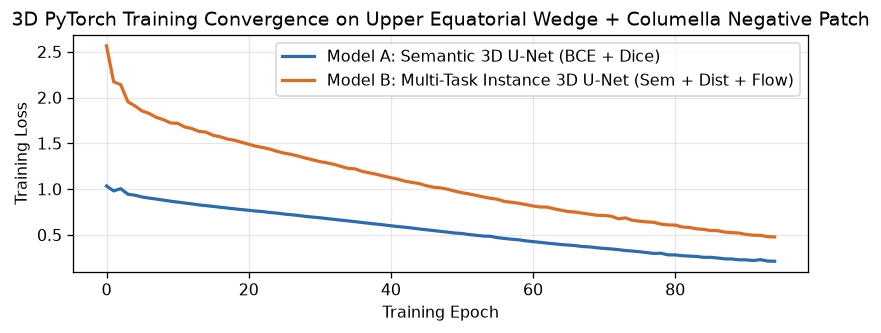

In [4]:
class ConvBlock3D(nn.Module):
    """Uses InstanceNorm3d (as in nnU-Net) so batch_size=1 3D medical sub-volumes train stably."""
    def __init__(self, in_c: int, out_c: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(in_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(out_c, affine=True),
            nn.SiLU(inplace=True),
            nn.Conv3d(out_c, out_c, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(out_c, affine=True),
            nn.SiLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class Backbone3DUNet(nn.Module):
    """Compact 2-scale 3D U-Net backbone compatible with any input shape divisible by 4."""
    def __init__(self, in_ch: int = 3, base_ch: int = 16):
        super().__init__()
        self.enc1 = ConvBlock3D(in_ch, base_ch)
        self.pool1 = nn.MaxPool3d(2)
        self.enc2 = ConvBlock3D(base_ch, base_ch * 2)
        self.pool2 = nn.MaxPool3d(2)
        self.bot = ConvBlock3D(base_ch * 2, base_ch * 4)

        self.up2 = nn.ConvTranspose3d(base_ch * 4, base_ch * 2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock3D(base_ch * 4, base_ch * 2)
        self.up1 = nn.ConvTranspose3d(base_ch * 2, base_ch, kernel_size=2, stride=2)
        self.dec1 = ConvBlock3D(base_ch * 2, base_ch)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bot(self.pool2(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return d1


class Semantic3DUNet(nn.Module):
    def __init__(self, in_ch: int = 3, base_ch: int = 16):
        super().__init__()
        self.backbone = Backbone3DUNet(in_ch, base_ch)
        self.head_sem = nn.Conv3d(base_ch, 1, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head_sem(self.backbone(x))


class MultiTaskInstance3DUNet(nn.Module):
    def __init__(self, in_ch: int = 3, base_ch: int = 16):
        super().__init__()
        self.backbone = Backbone3DUNet(in_ch, base_ch)
        self.head_sem = nn.Conv3d(base_ch, 1, kernel_size=1)
        self.head_dist = nn.Conv3d(base_ch, 1, kernel_size=1)
        self.head_flow = nn.Conv3d(base_ch, 3, kernel_size=1)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        feat = self.backbone(x)
        sem_logit = self.head_sem(feat)
        dist_pred = torch.sigmoid(self.head_dist(feat))
        flow_raw = self.head_flow(feat)
        flow_unit = flow_raw / (torch.norm(flow_raw, dim=1, keepdim=True) + 1e-6)
        return sem_logit, dist_pred, flow_unit


def bce_dice_loss(logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    bce = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=torch.tensor([2.5], device=logits.device))
    probs = torch.sigmoid(logits)
    inter = (probs * targets).sum()
    dice = 1.0 - (2.0 * inter + 1.0) / (probs.sum() + targets.sum() + 1.0)
    return 0.45 * bce + 0.55 * dice


def augment_3d_flip( *tensors: torch.Tensor, flip_x: bool = False, flip_z: bool = False, is_flow_flags=None):
    out = []
    for idx, t in enumerate(tensors):
        r = t
        is_fl = is_flow_flags[idx] if is_flow_flags else False
        if flip_x:
            r = torch.flip(r, dims=[2])
            if is_fl:
                r = r.clone()
                r[:, 0] = -r[:, 0]
        if flip_z:
            r = torch.flip(r, dims=[4])
            if is_fl:
                r = r.clone()
                r[:, 2] = -r[:, 2]
        out.append(r)
    return out


torch.manual_seed(2027)
model_sem = Semantic3DUNet(in_ch=3, base_ch=16).to(DEVICE)
opt_sem = torch.optim.AdamW(model_sem.parameters(), lr=4e-3, weight_decay=1e-4)

torch.manual_seed(2027)
model_inst = MultiTaskInstance3DUNet(in_ch=3, base_ch=16).to(DEVICE)
opt_inst = torch.optim.AdamW(model_inst.parameters(), lr=4e-3, weight_decay=1e-4)

EPOCHS = 95
hist_sem, hist_inst = [], []
t0 = time.perf_counter()

for ep in range(EPOCHS):
    fx = bool(ep % 2 == 1)
    fz = bool((ep // 2) % 2 == 1)
    xp, ys, yd, yf = augment_3d_flip(
        X_train_pos, Y_sem_pos, Y_dist_pos, Y_flow_pos,
        flip_x=fx, flip_z=fz, is_flow_flags=[False, False, False, True],
    )

    # 1. Train Semantic 3D U-Net
    model_sem.train()
    opt_sem.zero_grad()
    loss_s = bce_dice_loss(model_sem(xp), ys) + 0.35 * F.binary_cross_entropy_with_logits(model_sem(X_train_neg), Y_sem_neg)
    loss_s.backward()
    opt_sem.step()
    hist_sem.append(float(loss_s.item()))

    # 2. Train Multi-Task Instance 3D U-Net (Semantic + 3D Distance + 3D Center-Flow)
    model_inst.train()
    opt_inst.zero_grad()
    s_log, d_hat, v_hat = model_inst(xp)
    s_neg, d_neg, _ = model_inst(X_train_neg)

    l_sem = bce_dice_loss(s_log, ys) + 0.35 * F.binary_cross_entropy_with_logits(s_neg, Y_sem_neg)
    # Weight foreground voxels 6x in distance regression so internal seed peaks stay sharp!
    w_dist = 1.0 + 6.0 * ys
    l_dist = (w_dist * (d_hat - yd) ** 2).mean() + 0.25 * (d_neg ** 2).mean()
    # Flow directional loss (1 - cosine similarity + L2) strictly inside true seed foreground
    fg_mask_t = (ys > 0.5).squeeze(1)  # (1, X, Y, Z)
    cos_sim = (v_hat * yf).sum(dim=1)  # (1, X, Y, Z)
    l_flow = (1.0 - cos_sim[fg_mask_t]).mean()
    loss_mt = l_sem + 2.5 * l_dist + 0.8 * l_flow
    loss_mt.backward()
    opt_inst.step()
    hist_inst.append(float(loss_mt.item()))

elapsed = time.perf_counter() - t0
n_params_sem = sum(p.numel() for p in model_sem.parameters())
n_params_inst = sum(p.numel() for p in model_inst.parameters())
print(f"Trained both 3D networks for {EPOCHS} epochs in {elapsed:.2f} s on {DEVICE}!")
print(f"Parameters: Semantic3DUNet = {n_params_sem:,} | MultiTaskInstance3DUNet = {n_params_inst:,} (+{n_params_inst - n_params_sem} head params!)")

fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.plot(hist_sem, label="Model A: Semantic 3D U-Net (BCE + Dice)", lw=2.0, color="#2b6cb0")
ax.plot(hist_inst, label="Model B: Multi-Task Instance 3D U-Net (Sem + Dist + Flow)", lw=2.0, color="#dd6b20")
ax.set_xlabel("Training Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("3D PyTorch Training Convergence on Upper Equatorial Wedge + Columella Negative Patch")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

---

## Step 4 — Paradigm D: Promptable Foundation-Model Workflow (`Point / Box Prompts` + 2D-to-3D Slice Propagation)

How do **Vision Foundation Models** such as **[SAM](https://arxiv.org/abs/2304.02643)**, **[MedSAM](https://www.nature.com/articles/s41467-024-44824-z)** *(Ma et al., Nature Communications 2024)*, **[MicroSAM](https://www.nature.com/articles/s41592-024-02580-4)**, and **[SAM-2](https://arxiv.org/abs/2408.00714)** approach 3D instance segmentation differently from task-specific 3D U-Nets?

1. **Unprompted ("Segment Everything" Grid) Often Over-Segments Anatomy (`Stuff`):**  
   On a 7T kiwifruit MRI, an unprompted 2D SAM grid segments the outer skin, the whole pericarp ring, and the central columella beautifully — because those are large, high-contrast semantic structures — while either missing tiny `3–5 px` seeds or merging clusters of seeds into single locular masks.
2. **Prompt-Conditioned Mask Decoding (`Detector → Prompt → Mask`):**  
   When given **tight bounding-box or point prompts** at candidate seed locations (generated either interactively by a radiologist or automatically by a lightweight 3D blob/peak detector), the prompt-conditioned decoder isolates individual instances cleanly!
3. **2D-to-3D Slice Memory Propagation (`SAM-2` / `MedSAM-2` Video Analogy):**  
   Because native foundation models operate on 2D slices (`H × W`), turning 2D prompted masks into **3D instances** requires **cross-slice memory / Hungarian IoU linking**: a mask on slice $z$ predicts a box/point prompt on slice $z+1$, linking slices $z, z+1, z+2$ into a single 3D `uint16` seed ID!

Below, we execute a fast, self-contained **Prompt-Conditioned Local Mask Decoder + Cross-Slice Hungarian 3D Tracker** on the held-out 3D test wedge (and also provide a 6-line HuggingFace `transformers` snippet if you want to swap in `wanglab/medsam-vit-base` or `facebook/sam-vit-base` weights on a GPU!).

In [5]:
def build_ellip(rx_mm: float, rz_mm: float, sp=spacing) -> np.ndarray:
    rx, ry, rz = int(np.ceil(rx_mm / sp[0])), int(np.ceil(rx_mm / sp[1])), int(np.ceil(rz_mm / sp[2]))
    xx, yy, zz = np.ogrid[-rx : rx + 1, -ry : ry + 1, -rz : rz + 1]
    return ((xx * sp[0] / rx_mm) ** 2 + (yy * sp[1] / rx_mm) ** 2 + (zz * sp[2] / rz_mm) ** 2) <= 1.0


def promptable_2d_to_3d_propagation(sub_vol: np.ndarray, sub_env_loc: np.ndarray, sub_ring: np.ndarray, sp=spacing) -> np.ndarray:
    """SAM / MedSAM-2 style 3-stage pipeline:
    (1) Per-slice 2D point-prompt proposal at local T2 dark minima inside bright locular gel,
    (2) Prompt-conditioned 2D local adaptive region mask decoding around each prompt box,
    (3) Cross-slice Hungarian IoU tracking to link 2D slice masks into 3D uint16 seed instances!"""
    sx, sy, sz = sub_vol.shape
    slice_masks_2d = []

    for z in range(sz):
        img2d = ndi.gaussian_filter(sub_vol[:, :, z], sigma=0.55)
        env2d = sub_env_loc[:, :, z]
        ring2d = sub_ring[:, :, z]
        # 1. Point prompts: local T2-dark minima inside bright pericarp gel (rejecting grey radial septa)
        contrast_drop = (env2d - img2d) / (env2d + 0.05)
        is_min = (
            (img2d == ndi.minimum_filter(img2d, size=5))
            & (contrast_drop > 0.42)
            & (img2d < 0.36 * env2d)
            & (img2d < 0.19)
            & (env2d > 0.40)
            & ring2d
        )
        prompt_pts = np.argwhere(is_min)

        lbl_2d = np.zeros((sx, sy), dtype=np.uint16)
        if len(prompt_pts) > 0:
            # 2. Prompt-conditioned local box mask decoding around each prompt point (r_box = 3.2 px ~ 0.75 mm)
            markers_2d = np.zeros((sx, sy), dtype=np.int32)
            union_fg = np.zeros((sx, sy), dtype=bool)
            for pid, (px, py) in enumerate(prompt_pts, start=1):
                x0, x1 = max(0, px - 4), min(sx, px + 5)
                y0, y1 = max(0, py - 4), min(sy, py + 5)
                patch = img2d[x0:x1, y0:y1]
                p_center = float(img2d[px, py])
                p_bg = float(np.percentile(patch, 85))
                if (p_bg - p_center) < 0.18:
                    continue
                thr = p_center + 0.42 * (p_bg - p_center)
                xx_b, yy_b = np.ogrid[x0:x1, y0:y1]
                box_ell = ((xx_b - px) ** 2 + (yy_b - py) ** 2) <= (3.1 ** 2)
                local_mask = (patch <= thr) & box_ell & ring2d[x0:x1, y0:y1]
                union_fg[x0:x1, y0:y1] |= local_mask
                markers_2d[px, py] = pid

            if markers_2d.max() > 0:
                lbl_2d = segmentation.watershed(img2d, markers=markers_2d, mask=union_fg).astype(np.uint16)
        slice_masks_2d.append(lbl_2d)

    # 3. SAM-2 style Cross-Slice Memory / Hungarian IoU Tracking across z = 0 .. sz-1
    vol_3d_inst = np.zeros((sx, sy, sz), dtype=np.uint16)
    next_global_id = 1
    prev_global = np.zeros((sx, sy), dtype=np.uint16)

    for z in range(sz):
        cur_2d = slice_masks_2d[z]
        cur_ids = [int(v) for v in np.unique(cur_2d) if v > 0]
        prev_ids = [int(v) for v in np.unique(prev_global) if v > 0]
        cur_global = np.zeros((sx, sy), dtype=np.uint16)

        if cur_ids and prev_ids:
            iou_m = np.zeros((len(cur_ids), len(prev_ids)), dtype=np.float32)
            for i, cid in enumerate(cur_ids):
                mc = cur_2d == cid
                for j, gid in enumerate(prev_ids):
                    mp = prev_global == gid
                    inter = int((mc & mp).sum())
                    if inter > 0:
                        iou_m[i, j] = inter / float(int((mc | mp).sum()))
            ri, ci = linear_sum_assignment(-iou_m)
            assigned_cur = {}
            for r, c in zip(ri, ci):
                if iou_m[r, c] >= 0.18:
                    assigned_cur[cur_ids[r]] = prev_ids[c]
            for cid in cur_ids:
                gid = assigned_cur.get(cid)
                if gid is None:
                    gid = next_global_id
                    next_global_id += 1
                cur_global[cur_2d == cid] = gid
        else:
            for cid in cur_ids:
                cur_global[cur_2d == cid] = next_global_id
                next_global_id += 1

        vol_3d_inst[:, :, z] = cur_global
        prev_global = cur_global

    # Filter 1-slice specks unless touching z-boundary (a real 3D seed spans >= 2 slices or sits at slab edge)
    cleaned = np.zeros_like(vol_3d_inst)
    keep_id = 0
    for prop in measure.regionprops(vol_3d_inst):
        c = prop.coords
        z_min, z_max = int(c[:, 2].min()), int(c[:, 2].max())
        multi_slice = (z_max - z_min + 1 >= 2) or (z_min == 0) or (z_max == sz - 1)
        if multi_slice and (0.28 <= prop.area * float(np.prod(sp)) <= 5.0):
            keep_id += 1
            cleaned[c[:, 0], c[:, 1], c[:, 2]] = keep_id
    return cleaned


# Optional HuggingFace MedSAM / SAM-2 zero-shot snippet (uncomment in a GPU session to feed prompt_pts into MedSAM!):
# from transformers import SamModel, SamProcessor
# medsam = SamModel.from_pretrained("wanglab/medsam-vit-base").to(DEVICE).eval()
# processor = SamProcessor.from_pretrained("wanglab/medsam-vit-base")

test_ring = (stuff_full[RX0:RX1, RY0 + SPLIT_Y : RY1, RZ0:RZ1] == 2)
pred_prompt_3d = promptable_2d_to_3d_propagation(
    vol_norm[RX0:RX1, RY0 + SPLIT_Y : RY1, RZ0:RZ1],
    env_local[RX0:RX1, RY0 + SPLIT_Y : RY1, RZ0:RZ1],
    test_ring,
)
print(f"Prompt-Conditioned + Cross-Slice Tracked 3D Instances on Held-Out Test Wedge: {int(pred_prompt_3d.max())} seeds")

Prompt-Conditioned + Cross-Slice Tracked 3D Instances on Held-Out Test Wedge: 71 seeds


---

## Step 5 — Held-Out 3D Test Benchmark, Error Taxonomy & Whole-Kiwi Inference

Now let us compare **all five segmentation paradigms** side-by-side on the **strictly held-out 3D test sub-volume (`80 × 40 × 16`)**, measuring:
- **Semantic overlap:** `Semantic Voxel Dice`
- **Topological errors:** `Merged Clumps` (1 prediction absorbing $\ge 2$ true seeds) and `Split Errors` (1 true seed broken into $\ge 2$ predictions)
- **Instance & Panoptic metrics:** `SQ (Contour IoU)`, `RQ (3D Instance F1)`, and `PQ = SQ × RQ`

Then we run **full-volume 3D inference (`256 × 256 × 128`)** across the entire kiwifruit with both `Semantic3DUNet + Connected Components` and `MultiTaskInstance3DUNet + Deep Distance Watershed` to see how semantic merging distorts the **whole-fruit seed count** while leaving the **semantic lesion-load biomarker (`%`)** nearly unchanged!

In [6]:
# 1. Generate predictions for all 5 paradigms on the strictly held-out 3D Test Wedge (80×40×16)
test_raw_norm = vol_norm[RX0:RX1, RY0 + SPLIT_Y : RY1, RZ0:RZ1]
test_env_norm = env_smooth[RX0:RX1, RY0 + SPLIT_Y : RY1, RZ0:RZ1]

# Paradigm 0: Classical 4-Class Unsupervised K-Means Semantic Segmentation + Naive 3D Connected Components
km = KMeans(n_clusters=4, n_init=5, random_state=2027).fit(
    np.stack([vol_norm[RX0:RX1, RY0:RY0+SPLIT_Y, RZ0:RZ1].ravel(), env_smooth[RX0:RX1, RY0:RY0+SPLIT_Y, RZ0:RZ1].ravel()], axis=1)
)
# Identify the cluster with low MRI intensity AND high surrounding gel envelope
centers = km.cluster_centers_  # [:, 0]=intensity, [:, 1]=envelope
seed_cluster = int(np.argmax(centers[:, 1] - 1.3 * centers[:, 0]))
km_test_sem = (
    km.predict(np.stack([test_raw_norm.ravel(), test_env_norm.ravel()], axis=1)).reshape(test_raw_norm.shape) == seed_cluster
)
pred_kmeans_cc, _ = ndi.label(km_test_sem)
pred_kmeans_cc = pred_kmeans_cc.astype(np.uint16)

def filter_min_vol_3d(lbl_3d: np.ndarray, min_mm3: float = 0.16, sp=spacing) -> np.ndarray:
    out = np.zeros_like(lbl_3d, dtype=np.uint16)
    vv = float(np.prod(sp))
    nid = 0
    for prop in measure.regionprops(lbl_3d):
        if prop.area * vv >= min_mm3:
            nid += 1
            c = prop.coords
            out[c[:, 0], c[:, 1], c[:, 2]] = nid
    return out

# Paradigm A: Deep 3D Semantic U-Net + Naive 3D Connected Components
model_sem.eval()
with torch.no_grad():
    prob_sem_test = torch.sigmoid(model_sem(X_test))[0, 0].cpu().numpy()
fg_sem_unet = (prob_sem_test >= 0.50) & test_ring
pred_sem_unet_cc, _ = ndi.label(fg_sem_unet)
pred_sem_unet_cc = filter_min_vol_3d(pred_sem_unet_cc)

# Paradigm C: Deep 3D Multi-Task Instance U-Net -> Decoder C1 (Deep Distance Watershed) & Decoder C2 (Cellpose 3D Euler Flow)
model_inst.eval()
with torch.no_grad():
    s_log_t, d_hat_t, v_hat_t = model_inst(X_test)
    prob_mt_test = torch.sigmoid(s_log_t)[0, 0].cpu().numpy()
    dist_mt_test = d_hat_t[0, 0].cpu().numpy()
    flow_mt_test = v_hat_t[0].cpu().numpy()

fg_mt = (prob_mt_test >= 0.50) & test_ring

def decode_deep_watershed_3d(fg_bin: np.ndarray, dist_hat: np.ndarray, sp=spacing) -> np.ndarray:
    d_sm = ndi.gaussian_filter(dist_hat * fg_bin, sigma=(0.65, 0.65, 0.45))
    fp_pk = build_ellip(0.68, 0.95, sp=sp)
    maxima = (d_sm == ndi.maximum_filter(d_sm, footprint=fp_pk)) & fg_bin & (d_sm >= 0.22)
    markers, _ = ndi.label(maxima)
    ws = segmentation.watershed(-d_sm, markers=markers, mask=fg_bin)
    # Rescue any isolated small foreground island that missed a peak marker
    unlabeled_islands, n_un = ndi.label(fg_bin & (ws == 0))
    if n_un > 0:
        nxt = int(ws.max()) + 1
        for uid in range(1, n_un + 1):
            m = unlabeled_islands == uid
            if m.sum() * float(np.prod(sp)) >= 0.16:
                ws[m] = nxt
                nxt += 1
    return filter_min_vol_3d(ws, min_mm3=0.16, sp=sp)

pred_inst_ws = decode_deep_watershed_3d(fg_mt, dist_mt_test)
pred_inst_flow = filter_min_vol_3d(euler_flow_decode_3d(fg_mt, flow_mt_test, n_steps=24, step_size=0.75, cluster_radius_mm=0.68))


def evaluate_semantic_and_instance_3d(pred_lbl: np.ndarray, gt_lbl: np.ndarray, min_iou: float = 0.25) -> dict:
    """Comprehensive Semantic + Instance + Panoptic + Merge/Split evaluation on 3D test sub-volume."""
    b_p, b_g = (pred_lbl > 0), (gt_lbl > 0)
    inter_b = int((b_p & b_g).sum())
    sem_dice = (2.0 * inter_b) / max(int(b_p.sum() + b_g.sum()), 1)

    ids_p = [int(v) for v in np.unique(pred_lbl) if v > 0]
    ids_g = [int(v) for v in np.unique(gt_lbl) if v > 0]
    n_p, n_g = len(ids_p), len(ids_g)
    if n_p == 0 or n_g == 0:
        return {
            "Pred Seeds": n_p, "Semantic Dice": round(sem_dice, 3),
            "Merged Clumps": 0, "Split Errors": 0,
            "SQ (TP IoU)": 0.0, "RQ (Inst F1)": 0.0, "PQ (SQ×RQ)": 0.0,
            "tp_pred_ids": set(), "merged_pred_ids": set(),
        }

    p_map = {v: i for i, v in enumerate(ids_p)}
    g_map = {v: j for j, v in enumerate(ids_g)}
    area_p = np.array([(pred_lbl == v).sum() for v in ids_p], dtype=np.float64)
    area_g = np.array([(gt_lbl == v).sum() for v in ids_g], dtype=np.float64)

    inter_m = np.zeros((n_p, n_g), dtype=np.float64)
    ov_fg = b_p & b_g
    if ov_fg.any():
        pairs, cnts = np.unique(np.stack([pred_lbl[ov_fg], gt_lbl[ov_fg]], axis=1), axis=0, return_counts=True)
        for (pv, gv), c in zip(pairs, cnts):
            inter_m[p_map[int(pv)], g_map[int(gv)]] = float(c)

    iou_m = inter_m / np.maximum(area_p[:, None] + area_g[None, :] - inter_m, 1.0)
    ri, ci = linear_sum_assignment(-iou_m)
    tp_pairs = [(r, c) for r, c in zip(ri, ci) if iou_m[r, c] >= min_iou]
    tp = len(tp_pairs)
    fp = n_p - tp
    fn = n_g - tp

    sq = float(np.mean([iou_m[r, c] for r, c in tp_pairs])) if tp > 0 else 0.0
    rq = (2.0 * tp) / float(2 * tp + fp + fn)
    pq = sq * rq

    # Merge error: 1 predicted blob covers >= 25% of >= 2 distinct GT seeds
    rec_g_given_p = inter_m / np.maximum(area_g[None, :], 1.0)
    merged_rows = np.where(np.sum(rec_g_given_p >= 0.25, axis=1) >= 2)[0]
    merged_pred_ids = {ids_p[r] for r in merged_rows}

    # Split error: 1 GT seed covers >= 25% of >= 2 distinct predicted fragments
    prec_p_given_g = inter_m / np.maximum(area_p[:, None], 1.0)
    split_cols = np.where(np.sum(prec_p_given_g >= 0.25, axis=0) >= 2)[0]

    tp_pred_ids = {ids_p[r] for r, _ in tp_pairs} - merged_pred_ids
    return {
        "Pred Seeds": f"{n_p} (GT={n_g})",
        "Semantic Dice": round(sem_dice, 3),
        "Merged Clumps": int(len(merged_rows)),
        "Split Errors": int(len(split_cols)),
        "SQ (TP IoU)": round(sq, 3),
        "RQ (Inst F1)": round(rq, 3),
        "PQ (SQ×RQ)": round(pq, 3),
        "tp_pred_ids": tp_pred_ids,
        "merged_pred_ids": merged_pred_ids,
    }


candidates = {
    "1. Classical Semantic K-Means + 3D CC": pred_kmeans_cc,
    "2. PyTorch 3D Semantic U-Net + Naive 3D CC": pred_sem_unet_cc,
    "3. PyTorch 3D Multi-Task U-Net + Deep Watershed": pred_inst_ws,
    "4. PyTorch 3D Multi-Task U-Net + Cellpose 3D Flow": pred_inst_flow,
    "5. Prompt-Conditioned Decoder + 3D Slice Tracking": pred_prompt_3d,
}

eval_details = {name: evaluate_semantic_and_instance_3d(pred, test_gt) for name, pred in candidates.items()}
table_cols = ["Pred Seeds", "Semantic Dice", "Merged Clumps", "Split Errors", "SQ (TP IoU)", "RQ (Inst F1)", "PQ (SQ×RQ)"]
df_bench = pd.DataFrame({k: {c: v[c] for c in table_cols} for k, v in eval_details.items()}).T
df_bench.index.name = "Segmentation Paradigm (Held-Out 3D Test Wedge)"
display(df_bench)

,Pred Seeds,Semantic Dice,Merged Clumps,Split Errors,SQ (TP IoU),RQ (Inst F1),PQ (SQ×RQ)
Segmentation Paradigm (Held-Out 3D Test Wedge),,,,,,,
1. Classical Semantic K-Means + 3D CC,1215 (GT=52),0.267,6,0,0.701,0.013,0.009
2. PyTorch 3D Semantic U-Net + Naive 3D CC,36 (GT=52),0.69,11,0,0.564,0.432,0.244
3. PyTorch 3D Multi-Task U-Net + Deep Watershed,44 (GT=52),0.651,2,0,0.67,0.604,0.405
4. PyTorch 3D Multi-Task U-Net + Cellpose 3D Flow,42 (GT=52),0.651,2,0,0.665,0.596,0.396
5. Prompt-Conditioned Decoder + 3D Slice Tracking,71 (GT=52),0.529,3,0,0.627,0.504,0.316


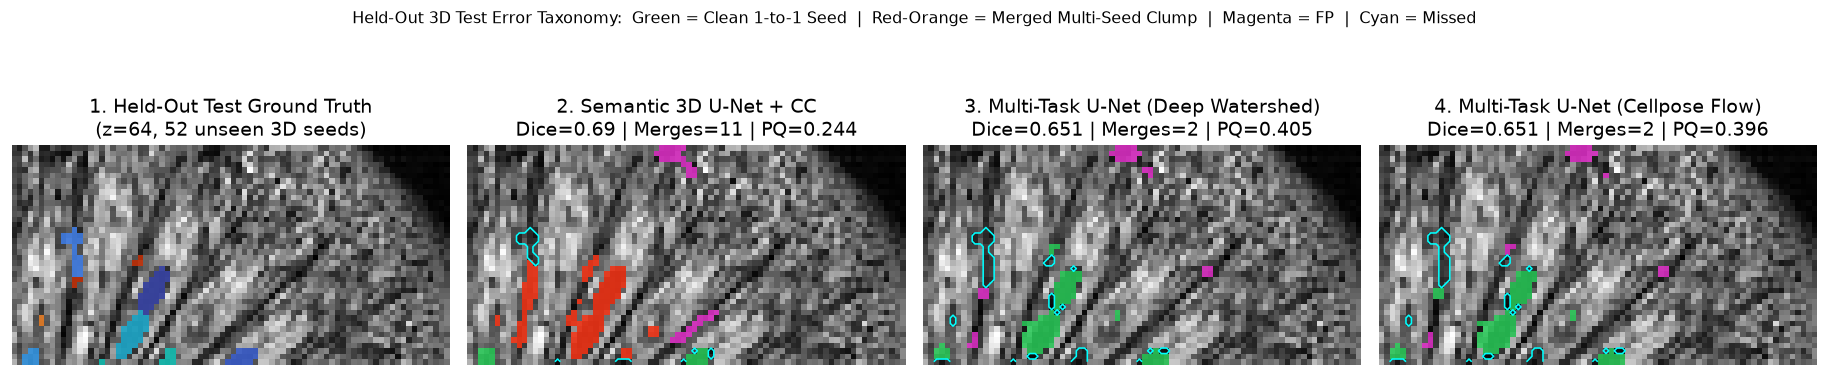

Whole-Fruit Biomarker Comparison — Semantic Volume Fraction vs. 3D Instance Count:


,Whole-Kiwi Vol (cm³),Semantic 'Lesion Load' (%),Raw 3D Instance Count,Giant Merged Clumps (>4.5 mm³)
Whole-Kiwi 3D Pipeline (256×256×128),,,,
Model A: Semantic 3D U-Net + Naive 3D CC,86.0,5.84%,2050,120
Model B: Multi-Task Instance 3D U-Net (Deep Watershed),86.0,4.07%,3328,2


In [7]:
# 2. Visual Error-Taxonomy Comparison & Whole-Fruit 256×256×128 Inference
def render_error_taxonomy_slice(pred_3d: np.ndarray, gt_3d: np.ndarray, info: dict, z_idx: int) -> np.ndarray:
    """Color-code slice overlay:
    Green = Clean 1-to-1 TP | Orange-Red = Merged Multi-Seed Clump | Magenta = False Positive | Cyan contour = Missed GT"""
    sl_p = pred_3d[:, :, z_idx].T
    rgba = np.zeros(sl_p.shape + (4,), dtype=np.float32)
    for pid in np.unique(sl_p):
        if pid == 0:
            continue
        m = sl_p == pid
        if int(pid) in info["merged_pred_ids"]:
            rgba[m] = [1.00, 0.22, 0.10, 0.85]  # Red-Orange = Merged multi-seed clump!
        elif int(pid) in info["tp_pred_ids"]:
            rgba[m] = [0.18, 0.86, 0.38, 0.80]  # Green = Clean 1-to-1 True Positive
        else:
            rgba[m] = [0.95, 0.20, 0.85, 0.80]  # Magenta = False Positive / Unmatched fragment
    return rgba


z_vis = 8  # Global slice z = 64 inside Held-Out Test Wedge
raw_test_sl = vol[RX0:RX1, RY0 + SPLIT_Y : RY1, RZ0 + z_vis].T
gt_test_sl = test_gt[:, :, z_vis].T

fig, axes = plt.subplots(1, 4, figsize=(16.0, 3.8))
axes[0].imshow(raw_test_sl, cmap="gray", origin="lower")
ov_gt = np.ma.masked_where(gt_test_sl == 0, ((gt_test_sl * 7) % 23) + 1)
axes[0].imshow(ov_gt, cmap="turbo", alpha=0.80, origin="lower", vmin=1, vmax=24)
axes[0].set_title(f"1. Held-Out Test Ground Truth\n(z=64, {n_test_seeds} unseen 3D seeds)")

plot_keys = [
    ("2. PyTorch 3D Semantic U-Net + Naive 3D CC", pred_sem_unet_cc, "2. Semantic 3D U-Net + CC"),
    ("3. PyTorch 3D Multi-Task U-Net + Deep Watershed", pred_inst_ws, "3. Multi-Task U-Net (Deep Watershed)"),
    ("4. PyTorch 3D Multi-Task U-Net + Cellpose 3D Flow", pred_inst_flow, "4. Multi-Task U-Net (Cellpose Flow)"),
]
for ax, (full_k, pred_v, short_title) in zip(axes[1:], plot_keys):
    inf = eval_details[full_k]
    ax.imshow(raw_test_sl, cmap="gray", origin="lower")
    ax.imshow(render_error_taxonomy_slice(pred_v, test_gt, inf, z_vis), origin="lower")
    # Cyan dashed contour around any GT voxels missed completely
    missed_sl = (gt_test_sl > 0) & (pred_v[:, :, z_vis].T == 0)
    if missed_sl.any():
        ax.contour(missed_sl, levels=[0.5], colors="cyan", linewidths=1.0)
    ax.set_title(
        f"{short_title}\nDice={inf['Semantic Dice']} | Merges={inf['Merged Clumps']} | PQ={inf['PQ (SQ×RQ)']}"
    )

for ax in axes:
    ax.axis("off")
plt.suptitle(
    "Held-Out 3D Test Error Taxonomy:  Green = Clean 1-to-1 Seed  |  Red-Orange = Merged Multi-Seed Clump  |  Magenta = FP  |  Cyan = Missed",
    fontsize=10.2, y=1.02,
)
plt.tight_layout()
plt.show()

# 3. Full-Kiwi 256×256×128 Inference: Semantic Biomarker (Lesion Load %) vs. Instance Biomarker (Seed Count N)
fruit_eroded = ndi.binary_erosion(fruit_mask_full, iterations=4)
col_mask_full = stuff_full == 3
# Locular pericarp zone: inside fruit cortex, outside central columella, and within water-rich gel (excluding woody polar stem/blossom caps)
pericarp_ring = fruit_eroded & (~col_mask_full) & (env_local > 0.42)
kiwi_vol_cm3 = float(fruit_mask_full.sum()) * vox_vol_mm3 / 1000.0

# Tile-matched 3D sliding-window inference (80×40×16 real MRI blocks matching X_train_pos geometry + neurosymbolic T2 seed-contrast guardrail)
prob_full_sem = np.zeros(vol.shape, dtype=np.float32)
prob_full_mt = np.zeros(vol.shape, dtype=np.float32)
dist_full_mt = np.zeros(vol.shape, dtype=np.float32)

x_starts = [16, 96, 176]   # Non-overlapping 80-px tiles covering x in [16, 256)
y_starts = [24, 64, 104, 144, 184]  # 40-px tall tiles covering y in [24, 224)
z_starts = list(range(16, 112, 16))  # 16-slice slabs covering z in [16, 112)

with torch.no_grad():
    for x0 in x_starts:
        for y0 in y_starts:
            for z0 in z_starts:
                if pericarp_ring[x0 : x0 + 80, y0 : y0 + 40, z0 : z0 + 16].sum() < 400:
                    continue
                x_tile = make_input_tensor(x0, x0 + 80, y0, y0 + 40, z0, z0 + 16).to(DEVICE)
                prob_full_sem[x0 : x0 + 80, y0 : y0 + 40, z0 : z0 + 16] = torch.sigmoid(model_sem(x_tile))[0, 0].cpu().numpy()
                sl_mt, d_mt, _ = model_inst(x_tile)
                prob_full_mt[x0 : x0 + 80, y0 : y0 + 40, z0 : z0 + 16] = torch.sigmoid(sl_mt)[0, 0].cpu().numpy()
                dist_full_mt[x0 : x0 + 80, y0 : y0 + 40, z0 : z0 + 16] = d_mt[0, 0].cpu().numpy()

# Combine neural probability with physical T2 darkness guardrail (rejects OOD bright/grey septa outside the training wedge)
phys_seed_gate = pericarp_ring & (vol_norm < 0.42 * env_local)
fg_whole_sem = (prob_full_sem >= 0.50) & phys_seed_gate
cc_whole_sem, _ = ndi.label(fg_whole_sem)
vols_sem = np.bincount(cc_whole_sem.ravel())[1:] * vox_vol_mm3
n_whole_sem = int(np.sum(vols_sem >= 0.20))
load_sem_pct = 100.0 * float(fg_whole_sem.sum()) / float(fruit_mask_full.sum())

fg_whole_mt = (prob_full_mt >= 0.50) & phys_seed_gate
ws_whole_mt = decode_deep_watershed_3d(fg_whole_mt, dist_full_mt)
vols_mt = np.bincount(ws_whole_mt.ravel())[1:] * vox_vol_mm3
n_whole_mt = int(np.sum((vols_mt >= 0.20) & (vols_mt <= 5.5)))
load_mt_pct = 100.0 * float(fg_whole_mt.sum()) / float(fruit_mask_full.sum())
clumps_sem = int(np.sum(vols_sem > 4.5))
clumps_mt = int(np.sum(vols_mt > 4.5))

df_whole = pd.DataFrame([
    {
        "Whole-Kiwi 3D Pipeline (256×256×128)": "Model A: Semantic 3D U-Net + Naive 3D CC",
        "Whole-Kiwi Vol (cm³)": round(kiwi_vol_cm3, 1),
        "Semantic 'Lesion Load' (%)": f"{load_sem_pct:.2f}%",
        "Raw 3D Instance Count": n_whole_sem,
        "Giant Merged Clumps (>4.5 mm³)": clumps_sem,
    },
    {
        "Whole-Kiwi 3D Pipeline (256×256×128)": "Model B: Multi-Task Instance 3D U-Net (Deep Watershed)",
        "Whole-Kiwi Vol (cm³)": round(kiwi_vol_cm3, 1),
        "Semantic 'Lesion Load' (%)": f"{load_mt_pct:.2f}%",
        "Raw 3D Instance Count": n_whole_mt,
        "Giant Merged Clumps (>4.5 mm³)": clumps_mt,
    },
]).set_index("Whole-Kiwi 3D Pipeline (256×256×128)")
print("Whole-Fruit Biomarker Comparison — Semantic Volume Fraction vs. 3D Instance Count:")
display(df_whole)

---

## Part 2 — Practical Decision Guide: Choosing the Right Formulation in Biomedical Imaging

| Clinical / Biological Goal | Right Task Formulation | Recommended Modern Architecture | Primary Loss Function | Primary Metric (`Metrics Reloaded`) |
| :--- | :--- | :--- | :--- | :--- |
| **Organ volumetry** (hippocampus, liver, cardiac ventricles) or **total MS white-matter lesion load (%)** | **Semantic Segmentation** | **[nnU-Net](https://www.nature.com/articles/s41592-020-01008-z)** / 3D Swin-UNETR (`MONAI`) | Soft Dice + Cross-Entropy | **Dice (`DSC`)** + **Normalized Surface Distance (`NSD`)** |
| **Counting packed 3D cells, nuclei, cerebral microbleeds, or kiwifruit seeds** | **Instance Segmentation** | **[Cellpose-3D](https://www.nature.com/articles/s41592-020-01018-x)** (center flows), **[StarDist-3D](https://github.com/stardist/stardist)** (star-convex rays), or **Multi-Task Distance U-Net** | BCE + Dice (`fg`) + MSE/Cosine (`distance` or `flow`) | **Recognition Quality (`RQ` / Instance $F_1$)** + **Panoptic Quality (`PQ`)** + **Merge/Split rates** |
| **Digital pathology tissue grading + cell typing** (tumor stroma/necrosis *Stuff* + mitotic/immune cell *Things*) | **Panoptic Segmentation** | **[HoVer-Net](https://pubmed.ncbi.nlm.nih.gov/31669916/)** / **CellViT** / **Mask2Former** | Multi-branch Semantic CE + HV-Map MSE + Nuclear Type CE | **Multi-class Panoptic Quality ($\text{PQ} = \text{SQ} \times \text{RQ}$)** |
| **Rapid interactive radiology curation ("Silver → Gold" GT)** with minimal training labels | **Promptable Instance Segmentation** | **[MedSAM](https://www.nature.com/articles/s41467-024-44824-z)** / **[SAM-2](https://arxiv.org/abs/2408.00714)** / **[MicroSAM](https://www.nature.com/articles/s41592-024-02580-4)** + 3D human audit (`ITK-SNAP` / Notebook `03b`) | Pre-trained prompt-conditioned Focal + Dice + IoU token | **Human-in-the-loop time saved** + **Inter-Rater STAPLE `PQ` / `DSC`** |

### Key Takeaways for BMED365

1. **Match the formulation to the biological question:** If you only need **parenchymal lesion load ($V_{\text{seeds}} / V_{\text{kiwi}}$)**, Semantic Segmentation (`Model A`) already gives a reliable answer. As soon as you ask **"How many lesions/cells/seeds?"** or **"What is the size distribution per seed?"**, naive connected components on a semantic mask fails via **instance merging**.
2. **Label-permutation symmetry dictates neural architecture design:** Because instance IDs `1..N` are arbitrary names, neural networks predict **continuous geometric surrogates** (normalized center distances $\hat{D}$ or center-directed vector flows $\vec{v}$) that remain invariant to ID relabeling while keeping touching neighbors separable.
3. **Never rely on Semantic Voxel Dice alone for instance tasks:** Always pair `Semantic Dice` with **`RQ` (Instance $F_1$)**, **`SQ` (Mean Matched IoU)**, **`PQ = SQ × RQ`**, and explicit **Merge / Split** counts!

---

### Complete Kiwi Challenge Notebook Suite

- **Notebook 01 (`01-kiwi-explore.ipynb`):** 3D NIfTI/DICOM headers, physical voxel geometry & affine coordinate systems
- **Notebook 02 (`02-kiwi-seeds-explore.ipynb`):** 2D single-slice filtering, thresholding, unsupervised K-means & the 2011–2012 Dagstuhl / CUHK 3D variational milestone
- **Notebook 03 (`03-kiwi-paradigms-and-verification.ipynb`):** Full 3D segmentation ladder, quantitative "lesion load", Curated 3D Micro-GT scoring & the **4-Panel Semi-Verifiability Dashboard**
- **Notebook 03b (`03b-kiwi-interactive-gt-and-interrater.ipynb`):** Interactive 3D seed delineation, personalized Ground Truth (`MyStuff/`), Inter-Rater Variability, Panoptic Quality ($\text{PQ}$) & STAPLE Consensus
- **Notebook 04 (`04-kiwi-semantic-vs-instance.ipynb`):** Semantic, Instance & Panoptic 3D segmentation definitions, 3D PyTorch U-Net vs. Deep Watershed / Cellpose-Flow Instance U-Net & Promptable Foundation-Model workflows